<a href="https://colab.research.google.com/github/Veniveni123/CSA47-DEEP-LEARNING/blob/main/LAB%2011-20/Experiment%2011%3A%20CNN%20for%20Image%20Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1947s 11us/step


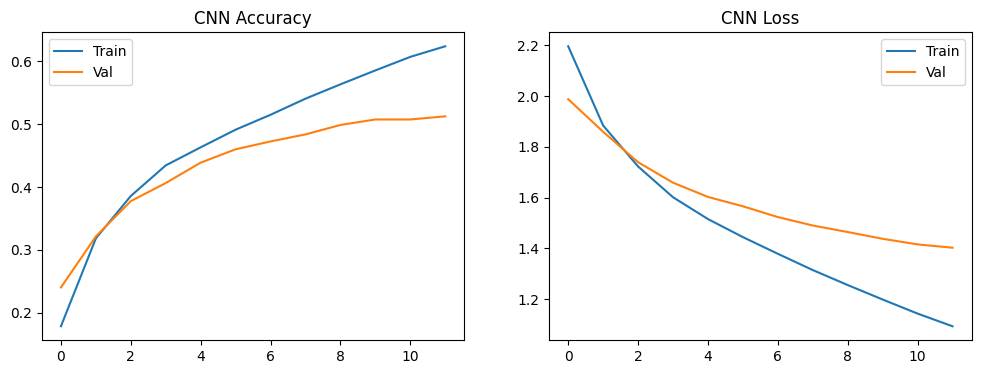

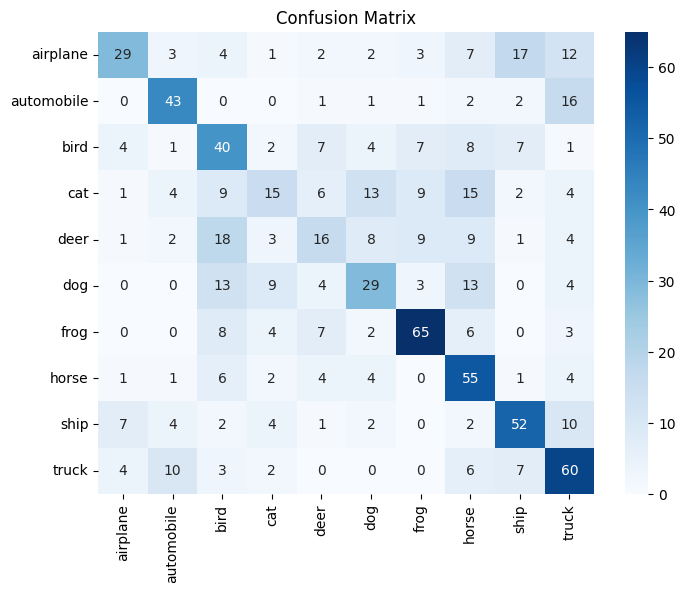

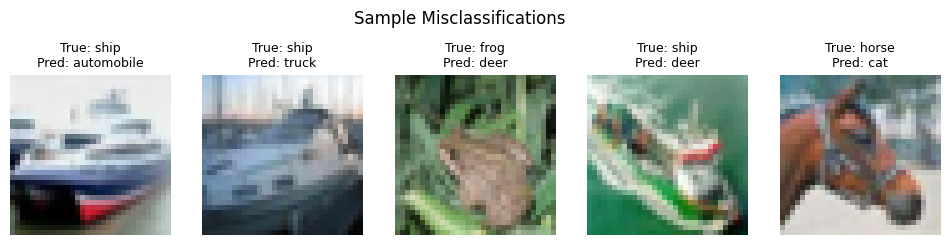

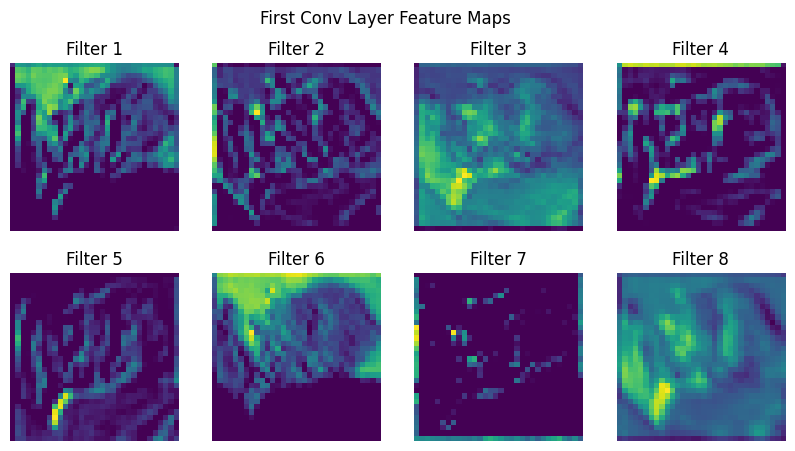

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import tensorflow as tf
from tensorflow import keras

np.random.seed(42)
tf.random.set_seed(42)

(X_full, y_full), (X_test_full, y_test_full) = keras.datasets.cifar10.load_data()
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

X_full = X_full[:4000].astype('float32') / 255.0
y_full = y_full[:4000].ravel()
X_train, X_val = X_full[:3200], X_full[3200:]
y_train, y_val = y_full[:3200], y_full[3200:]
X_test = X_test_full[:800].astype('float32') / 255.0
y_test = y_test_full[:800].ravel()

inputs = keras.Input(shape=(32, 32, 3))
c1 = keras.layers.Conv2D(16, (3, 3), activation='relu', padding='same', name='conv1')(inputs)
p1 = keras.layers.MaxPooling2D((2, 2))(c1)
c2 = keras.layers.Conv2D(32, (3, 3), activation='relu', padding='same')(p1)
p2 = keras.layers.MaxPooling2D((2, 2))(c2)
flat = keras.layers.Flatten()(p2)
d1 = keras.layers.Dense(64, activation='relu')(flat)
outputs = keras.layers.Dense(10, activation='softmax')(d1)

cnn = keras.Model(inputs, outputs)
cnn.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
hist = cnn.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=12, batch_size=64, verbose=0)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist.history['accuracy'], label='Train'); axes[0].plot(hist.history['val_accuracy'], label='Val')
axes[0].set_title("CNN Accuracy"); axes[0].legend()
axes[1].plot(hist.history['loss'], label='Train'); axes[1].plot(hist.history['val_loss'], label='Val')
axes[1].set_title("CNN Loss"); axes[1].legend()
plt.show()

y_pred = np.argmax(cnn.predict(X_test, verbose=0), axis=1)
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix")
plt.show()

mis_idx = np.where(y_pred != y_test)[0][:5]
fig, axes = plt.subplots(1, 5, figsize=(12, 3))
for ax, idx in zip(axes, mis_idx):
    ax.imshow(X_test[idx])
    ax.set_title(f"True: {class_names[y_test[idx]]}\nPred: {class_names[y_pred[idx]]}", fontsize=9)
    ax.axis('off')
plt.suptitle("Sample Misclassifications")
plt.show()

feat_extractor = keras.Model(inputs=cnn.input, outputs=cnn.get_layer('conv1').output)
fmaps = feat_extractor.predict(X_test[:1], verbose=0)[0]
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(fmaps[:, :, i], cmap='viridis')
    ax.set_title(f"Filter {i+1}")
    ax.axis('off')
plt.suptitle("First Conv Layer Feature Maps")
plt.show()